# Surf Maneuver Recognition: Linear Probe

A logistic regression on frozen V-JEPA 2 features: the simplest classifier, used as a baseline and to measure
how much the original split's leakage inflates test scores.

## 1. Data

Each clip's (8, 1024) features are averaged over time into a single 1024-dimensional vector.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path("..").resolve()

splits = pd.read_csv(PROJECT_ROOT / "data" / "splits.csv")
saved = np.load(PROJECT_ROOT / "data" / "processed" / "vjepa2_vitl_t8.npz")
features_by_clip = dict(zip(saved["clips"], saved["features"]))

# Rows aligned with splits.csv
X_time = np.stack([features_by_clip[c] for c in splits["clip"]])   # (1056, 8, 1024)
X = X_time.mean(axis=1)                                               # (1056, 1024)
y = splits["maneuver"].to_numpy()
print(X.shape, y.shape)

(1056, 1024) (1056,)


## 2. Original split vs. session-aware split

The same classifier is trained on the training set and evaluated on the test set of each split.
Validation is not used yet; hyperparameters stay at their defaults.
Note: the original split here excludes the 6 label-conflict rows, so both splits use the same 1056 clips.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def train_and_test(split_column):
    """Fit a linear probe on the train subset of a split and score it on its test subset."""
    train = (splits[split_column] == "train").to_numpy()
    test = (splits[split_column] == "test").to_numpy()
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000, class_weight="balanced"),
    )
    probe.fit(X[train], y[train])
    predictions = probe.predict(X[test])
    scores = {
        "test clips": int(test.sum()),
        "accuracy": accuracy_score(y[test], predictions),
        "macro F1": f1_score(y[test], predictions, average="macro"),
    }
    return scores, probe, predictions

results = {}
for column, name in [("original_split", "original"), ("split", "session-aware")]:
    results[name], _, _ = train_and_test(column)

pd.DataFrame(results).T.round(3)

,test clips,accuracy,macro F1
original,211.0,0.886,0.886
session-aware,236.0,0.852,0.856


## 3. Errors on the session-aware test set

Per-maneuver scores and the confusion matrix show which maneuvers the probe mixes up.

                   precision    recall  f1-score   support

              360      0.918     0.776     0.841        58
cutback-frontside      0.750     0.702     0.725        47
           roller      0.839     0.925     0.880       107
         take-off      0.960     1.000     0.980        24

         accuracy                          0.852       236
        macro avg      0.867     0.851     0.856       236
     weighted avg      0.853     0.852     0.850       236



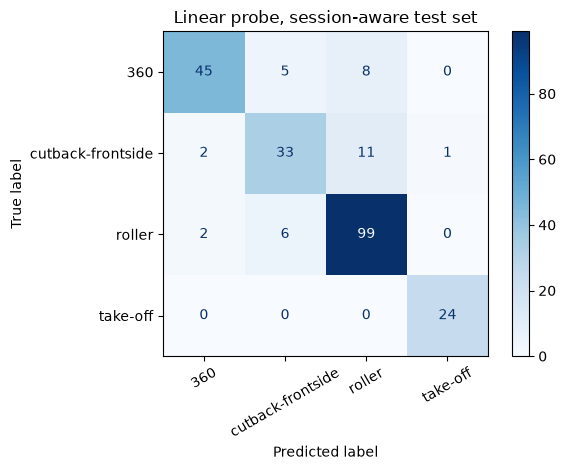

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

scores, probe, predictions = train_and_test("split")
test = (splits["split"] == "test").to_numpy()

print(classification_report(y[test], predictions, digits=3))

ConfusionMatrixDisplay.from_predictions(y[test], predictions, cmap="Blues", xticks_rotation=30)
plt.title("Linear probe, session-aware test set")
plt.tight_layout()
plt.show()

## 4. Findings

- A linear probe on frozen V-JEPA 2 features reaches **85.2% accuracy and 0.856 macro F1** on sessions never seen in training
  (chance: 25%; always predicting "roller": about 45%).
- On the original split, the same probe scores 88.6% / 0.886. The 3-point gap is consistent with leakage, but a single split
  cannot separate it from sampling noise (the two test sets contain different clips); repeated splits will settle it.
- **Take-off is perfect (24/24)**, possibly helped by scene shortcuts (several take-offs come from one wave pool session). To be checked.
- **Cutback is the weakest class (F1 0.725):** 11 of 47 cutbacks are predicted as roller. Both are turns on the wave face and differ
  mainly in the order of movements, which time-averaging discards. A temporal probe over the 8 time slices is the next step.